In [1]:
#chargement
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

DATA_DIR = Path("../data")
df = pd.read_csv(DATA_DIR / "raw" / "chanel_with_paths.csv")
print(df.shape)
print("Images disponibles :", df["image_ok"].sum())

(1428, 19)
Images disponibles : 918


In [2]:
#colonnes constantes et vals manquantes
for c in ["website_name", "country_code", "currency_code", "brand"]:
    print(c, df[c].unique())

print("\nDates :", df["competence_date"].unique())
print("\nValeurs manquantes :")
print(df.isna().sum()[df.isna().sum() > 0])

website_name <ArrowStringArray>
['Chanel']
Length: 1, dtype: str
country_code <ArrowStringArray>
['DEU']
Length: 1, dtype: str
currency_code <ArrowStringArray>
['EUR']
Length: 1, dtype: str
brand <ArrowStringArray>
['CHANEL']
Length: 1, dtype: str

Dates : <ArrowStringArray>
['2023-11-17']
Length: 1, dtype: str

Valeurs manquantes :
Series([], dtype: int64)


In [3]:
#les 3 niveaux de catégories
pd.set_option("display.max_rows", None)
for c in ["category1_code", "category2_code", "category3_code"]:
    print(f"\n--- {c} : {df[c].nunique()} classes ---")
    print(df[c].value_counts(dropna=False))


--- category1_code : 7 classes ---
category1_code
FASHION      550
FRAGRANCE    199
JEWELRY      193
EYEWEAR      163
MAKEUP       121
SKINCARE     104
WATCHES       98
Name: count, dtype: int64

--- category2_code : 51 classes ---
category2_code
READY-TO-WEAR                  243
COSTUME JEWELRY                127
SUNGLASSES                      99
WOMEN                           88
WATCHES                         87
MEN                             72
HANDBAGS                        61
COCO CRUSH                      54
SHOES                           42
FACE                            41
EYEGLASSES                      40
SMALL LEATHER GOODS             38
BATH AND BODY                   36
RINGS                           35
EYES                            35
MOISTURIZERS                    35
NECKLACES                       30
EARRINGS                        26
BRUSHES AND ACCESSORIES         26
BLUE LIGHT GLASSES              24
LIPS                            21
N°5              

count      1428.000000
mean       6076.253725
std       15219.005999
min          23.000000
25%         195.000000
50%        1415.000000
75%        5800.000000
max      142000.000000
Name: price_eur, dtype: float64


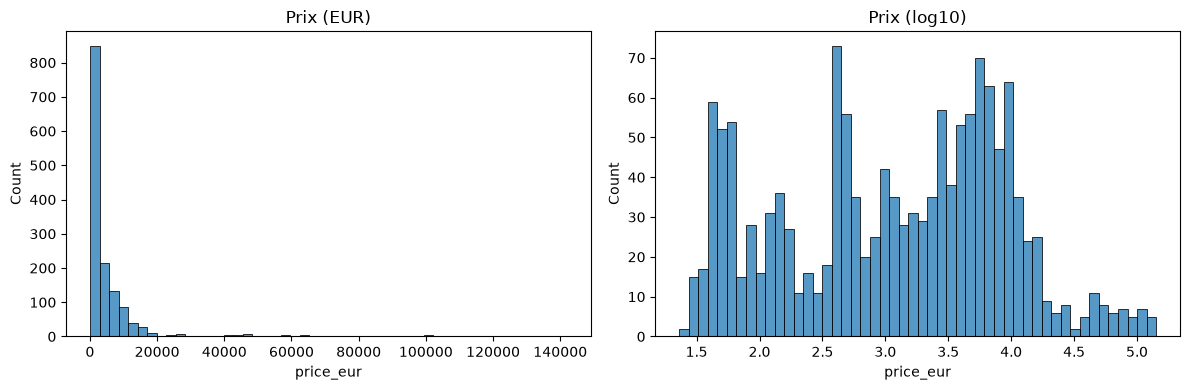

In [4]:
#prix
print(df["price_eur"].describe())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["price_eur"], bins=50, ax=ax[0])
ax[0].set_title("Prix (EUR)")
sns.histplot(np.log10(df["price_eur"].dropna()), bins=50, ax=ax[1])
ax[1].set_title("Prix (log10)")
plt.tight_layout()
plt.show()

In [5]:
#longueur des titres
df["title_len_words"] = df["title"].fillna("").str.split().str.len()
df["title_len_chars"] = df["title"].fillna("").str.len()
print(df[["title_len_words", "title_len_chars"]].describe())

print("\nTitres courts :", df.nsmallest(5, "title_len_chars")["title"].tolist())
print("\nExemples :")
print(df["title"].sample(15, random_state=0).to_string())
print("\nTitres vides ou 'n.a.' :", (df["title"].isna() | df["title"].str.lower().eq("n.a.")).sum())

       title_len_words  title_len_chars
count      1428.000000      1428.000000
mean          5.094538        39.056022
std           2.519752        20.365571
min           1.000000         4.000000
25%           3.000000        26.000000
50%           5.000000        36.000000
75%           7.000000        51.000000
max          19.000000       162.000000

Titres courts : ['n.a.', 'Blau', 'n.a.', 'n.a.', 'n.a.']

Exemples :
459                        Steppmotiv  18 Karat BEIGEGOLD
822                             18 Karat Rotgold  Diamant
445                          18 Karat Weißgold  Diamanten
911               Metall & Glasperlen  Goldfarben & Braun
530     Metall  Strass & Glasperlen  Silberfarben  Kri...
540                Lammfell & silberfarbenes Metall  Weiß
1146       Dunkles Schildpatt. Gläser: Braun  Mit Verlauf
326                      Bedruckter Denim  Schwarz & Weiß
231                          Samt  Schwarz & silberfarben
1127      Schwarz. Gläser: Grau  Polarisiert  Mi